In [ ]:
!git clone https://github.com/rbborowski/Thesis.git

fatal: destination path 'Thesis' already exists and is not an empty directory.


In [ ]:
import os
import pandas as pd
from google.colab import userdata

# 1. Puxa a nova variável de ambiente diretamente dos secrets
os.environ["KAGGLE_API_TOKEN"] = userdata.get('KAGGLE_API_TOKEN')

# 2. Baixa APENAS o arquivo de artigos da competição
!kaggle competitions download -c h-and-m-personalized-fashion-recommendations -f articles.csv

# 3. Descompacta o arquivo baixado
!unzip -o articles.csv.zip

# 4. Carrega os dados no dataframe
df_articles = pd.read_csv('articles.csv')
display(df_articles.head())

articles.csv.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  articles.csv.zip
  inflating: articles.csv            


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,...,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,...,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


### Step 1: Label-Space Analysis (Section 4.2 of the Thesis)
We need to enumerate the distinct values and record their frequency for candidate filterable fields. Based on the thesis, we expect `product_type_name`, `colour_group_name`, and `index_group_name` (audience) to be strong candidates for **hard filters**.

In [ ]:
# Identify potential fields for hard filtering vs soft intent
candidate_fields = [
    'product_type_name',
    'colour_group_name',
    'index_group_name', # Intended audience
    'garment_group_name',
    'section_name'
]

print("--- Label Space Analysis ---\n")
for field in candidate_fields:
    if field in df_articles.columns:
        unique_count = df_articles[field].nunique()
        print(f"\n{'='*40}")
        print(f"Field: {field} | Unique values: {unique_count}")
        print(f"{'='*40}")

        # Display top 10 most frequent values to understand the distribution
        top_values = df_articles[field].value_counts().head(10)
        print(top_values.to_string())
    else:
        print(f"Field {field} not found in the dataset.")


--- Label Space Analysis ---


Field: product_type_name | Unique values: 131
product_type_name
Trousers    11169
Dress       10362
Sweater      9302
T-shirt      7904
Top          4155
Blouse       3979
Jacket       3940
Shorts       3939
Shirt        3405
Vest top     2991

Field: colour_group_name | Unique values: 50
colour_group_name
Black             22670
Dark Blue         12171
White              9542
Light Pink         5811
Grey               4487
Light Beige        3356
Blue               3308
Red                3056
Light Blue         3012
Greenish Khaki     2767

Field: index_group_name | Unique values: 5
index_group_name
Ladieswear       39737
Baby/Children    34711
Divided          15149
Menswear         12553
Sport             3392

Field: garment_group_name | Unique values: 21
garment_group_name
Jersey Fancy         21445
Accessories          11519
Jersey Basic          8126
Knitwear              7490
Under-, Nightwear     7441
Trousers              6727
Blouses          

### Step 2: Setting up Free AI Models
Next, we will install `sentence-transformers` for the baseline dense retrieval (embedding generation) and `google-generativeai` to act as our LLM for extracting the hard filters from the query.

In [ ]:
!pip install -q sentence-transformers
!pip install -q transformers accelerate
print("Libraries installed successfully!")

Libraries installed successfully!


### Step 3: Baseline System - Embedding Setup (Section 4.3)
We will use `sentence-transformers` to embed the product descriptions. We'll concatenate the metadata fields to the description to ensure a fair comparison with the hybrid system, as specified in the thesis.

In [ ]:
from sentence_transformers import SentenceTransformer
import pandas as pd
import numpy as np

# Initialize a small, fast, and free embedding model
embedder = SentenceTransformer('all-MiniLM-L6-v2')

# Prepare the text to embed (concatenating metadata + description)
# For performance in this demo, let's take a sample of the catalog
df_sample = df_articles.dropna(subset=['detail_desc']).sample(10000, random_state=42).copy()

# Enriched data representation for better Dense Retrieval matching
df_sample['text_for_embedding'] = (
    "Name: " + df_sample['prod_name'].fillna('') + ". " +
    "Type: " + df_sample['product_type_name'].fillna('') + ". " +
    "Category: " + df_sample['product_group_name'].fillna('') + ". " +
    "Garment: " + df_sample['garment_group_name'].fillna('') + ". " +
    "Section: " + df_sample['section_name'].fillna('') + ". " +
    "Color: " + df_sample['colour_group_name'].fillna('') + ". " +
    "Audience: " + df_sample['index_group_name'].fillna('') + ". " +
    "Description: " + df_sample['detail_desc']
)

print("Embedding products with enriched data... This might take a minute.")
# Embed the catalog
product_embeddings = embedder.encode(df_sample['text_for_embedding'].tolist(), show_progress_bar=True)
print("Embeddings generated!")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding products with enriched data... This might take a minute.


Batches:   0%|          | 0/313 [00:00<?, ?it/s]

Embeddings generated!


### Step 4: Hybrid System - LLM Query Parser (Section 4.4)
Now we set up Gemini to extract structured hard filters (`product_type_name`, `colour_group_name`, `index_group_name`) and the residual `soft_intent`. You need to add your Gemini API key to the Colab Secrets as `GOOGLE_API_KEY`.

In [ ]:
import torch
from transformers import pipeline
import json

# Only load if not already loaded to save time
if 'pipe' not in globals():
    print("Loading Qwen/Qwen2.5-1.5B-Instruct... (this might take a minute)")
    pipe = pipeline(
        "text-generation",
        model="Qwen/Qwen2.5-1.5B-Instruct",
        model_kwargs={"torch_dtype": torch.bfloat16},
        device_map="auto"
    )
    print("Local LLM loaded successfully!")

def parse_query_with_llm(query, schema):
    prompt = f"""<|im_start|>system
You are an expert fashion AI assistant. Your goal is to help retrieve clothing items based on aesthetics, vibes, and specific requests.
Return ONLY valid JSON matching this schema:
{json.dumps(schema, indent=2)}
<|im_end|>
<|im_start|>user
Analyze the following search query: "{query}"

1. HARD FILTERS: Think carefully about what to filter based on the user's query and the available dataset fields: 'product_type_name' (e.g., dress, trousers, sweater), 'colour_group_name' (e.g., black, pink, white), and 'index_group_name' (target audience, e.g., Ladieswear, Menswear, Divided, Baby/Children, Sport).
Extract explicit constraints. ADDITIONALLY, if the query represents an aesthetic or pop culture reference, deduce any highly probable implicit constraints for ANY of these fields. For example, 'Legally Blonde' implies 'colour_group_name': 'pink' and 'index_group_name': 'Ladieswear'. 'Skaterboy' implies 'Menswear' or 'Divided'. Only fill fields you can confidently deduce; otherwise, leave them null.
2. EXPANDED QUERY: Write a rich, descriptive paragraph capturing the aesthetic, vibe, typical colors, fabrics, and specific items. CRITICAL: Translate the requested aesthetic into literal retail and e-commerce jargon keywords (e.g., 'frilled', 'pastel', 'pleated skirt', 'puff sleeve', 'rib-knit'). Make it highly descriptive as it will be used for vector similarity matching against standard fashion product descriptions!
<|im_end|>
<|im_start|>assistant
"""
    outputs = pipe(prompt, max_new_tokens=250, return_full_text=False, temperature=0.3, do_sample=True)
    response_text = outputs[0]["generated_text"].strip()

    try:
        # Clean up markdown formatting if present
        text = response_text.replace('```json', '').replace('```', '').strip()
        return json.loads(text)
    except Exception as e:
        print(f"Failed to parse LLM output: {response_text}")
        return None

# Define the schema to focus on Query Expansion
schema = {
  "hard_filters": {
    "product_type_name": "string or null",
    "colour_group_name": "string or null",
    "index_group_name": "string or null"
  },
  "expanded_query": "string (rich description of aesthetic using retail jargon)"
}

# Test the parser with one of the tricky queries
test_query = "legally blonde"
print(f"\nTesting parser with query: '{test_query}'")
parsed_result = parse_query_with_llm(test_query, schema)
if parsed_result:
    print(json.dumps(parsed_result, indent=2))


[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



Testing parser with query: 'legally blonde'
{
  "hard_filters": {
    "product_type_name": null,
    "colour_group_name": "pink",
    "index_group_name": "Ladieswear"
  },
  "expanded_query": "A chic, pastel-toned ensemble with soft, flowing textures that exude femininity and sophistication. Ideal for daytime wear, featuring delicate pleats, frills, and voluminous skirts. Perfect for women who appreciate classic elegance without compromising comfort."
}


### Step 5: Hybrid Search Pipeline (Section 4.5)
Here we implement the core hybrid pipeline. It filters the dataset using the structured `hard_filters` and then performs vector search on the `soft_intent` against the remaining candidates.

In [ ]:
from sentence_transformers import util
import numpy as np

def hybrid_search(query, top_k=5, min_results=1):
    print(f"--- Hybrid Search Query: '{query}' ---")

    # 1. Parse Query
    parsed = parse_query_with_llm(query, schema)
    if not parsed:
        return None

    hard_filters = parsed.get("hard_filters", {})
    expanded_query = parsed.get("expanded_query", "")

    # Basic synonym mapping to handle common user terms vs catalog terms
    if hard_filters.get('product_type_name'):
        if 'jean' in hard_filters['product_type_name'].lower():
            hard_filters['product_type_name'] = 'Trousers'

    print("Original Hard Filters:", {k: v for k, v in hard_filters.items() if v})
    print("Expanded Query for Dense Search:", expanded_query)

    # 2. Apply Hard Filters with Relaxation
    active_filters = {k: v for k, v in hard_filters.items() if v}
    # Define order of relaxation (drop least critical first)
    relaxation_order = ['colour_group_name', 'index_group_name', 'product_type_name']

    while True:
        current_filtered_df = df_sample.copy().reset_index(drop=True)
        current_filtered_indices = np.arange(len(current_filtered_df))

        for field, value in active_filters.items():
            if field in current_filtered_df.columns:
                mask = current_filtered_df[field].astype(str).str.contains(str(value), case=False, na=False)
                current_filtered_df = current_filtered_df[mask]
                current_filtered_indices = current_filtered_indices[mask]

        if len(current_filtered_df) >= min_results or len(active_filters) == 0:
            filtered_df = current_filtered_df
            filtered_indices = current_filtered_indices
            break

        # Relax the least important filter currently active
        relaxed = False
        for field in relaxation_order:
            if field in active_filters:
                print(f"-> Candidate set too small ({len(current_filtered_df)}). Relaxing filter: {field}")
                del active_filters[field]
                relaxed = True
                break

        if not relaxed:
            filtered_df = current_filtered_df
            filtered_indices = current_filtered_indices
            break

    print(f"Items remaining after hard filtering: {len(filtered_df)}\n")

    if len(filtered_df) == 0:
        print("No items match the query even after relaxation.")
        return filtered_df

    # 3. Dense Retrieval on Expanded Query
    columns_to_show = ['article_id', 'prod_name', 'product_type_name', 'colour_group_name', 'detail_desc']

    # Fallback to original query if LLM didn't produce an expanded query
    search_text = expanded_query if expanded_query else query

    query_embedding = embedder.encode(search_text)
    filtered_embeddings = product_embeddings[filtered_indices]

    # Compute cosine similarity
    cos_scores = util.cos_sim(query_embedding, filtered_embeddings)[0]
    filtered_df['similarity_score'] = cos_scores.cpu().numpy()

    columns_to_show.append('similarity_score')
    results = filtered_df.sort_values('similarity_score', ascending=False).head(top_k)

    return results[columns_to_show]

### Step 6: Baseline vs. Hybrid Comparison (Section 5)
Let's compare our new hybrid system against a standard baseline approach where the entire query is just fed directly into the dense retriever.

In [ ]:
def baseline_search(query, top_k=5):
    print(f"--- Baseline Search Query: '{query}' ---")
    query_embedding = embedder.encode(query)
    cos_scores = util.cos_sim(query_embedding, product_embeddings)[0]

    df_baseline = df_sample.copy().reset_index(drop=True)
    df_baseline['similarity_score'] = cos_scores.cpu().numpy()

    columns_to_show = ['article_id', 'prod_name', 'product_type_name', 'colour_group_name', 'detail_desc', 'similarity_score']
    return df_baseline.sort_values('similarity_score', ascending=False).head(top_k)[columns_to_show]

# Run the comparison
test_query = "a flowy black midi dress for a summer wedding"

print("==================== HYBRID SYSTEM ====================")
hybrid_results = hybrid_search(test_query, top_k=3)
display(hybrid_results)

print("\n==================== BASELINE SYSTEM ====================")
baseline_results = baseline_search(test_query, top_k=3)
display(baseline_results)

[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


==================== HYBRID SYSTEM ====================
--- Hybrid Search Query: 'a flowy black midi dress for a summer wedding' ---
Original Hard Filters: {'product_type_name': 'dress', 'colour_group_name': 'black', 'index_group_name': 'flowy'}
Soft Intent for Dense Search: summer wedding
-> Candidate set too small (0). Relaxing filter: colour_group_name
-> Candidate set too small (0). Relaxing filter: index_group_name
Items remaining after hard filtering: 1004



,article_id,prod_name,product_type_name,colour_group_name,detail_desc,similarity_score
9140,784878001,Endive Wedding Dress,Dress,Off White,Long wedding dress in a sturdy weave with a de...,0.391566
6905,811768001,Ruby dress,Dress,Light Pink,"Dress in a soft, patterned cotton weave with b...",0.321677
3228,619353007,Vilde dress,Dress,Dark Blue,"Short-sleeved dress in soft, fine-knit cotton ...",0.319551



==================== BASELINE SYSTEM ====================
--- Baseline Search Query: 'a flowy black midi dress for a summer wedding' ---


,article_id,prod_name,product_type_name,colour_group_name,detail_desc,similarity_score
9140,784878001,Endive Wedding Dress,Dress,Off White,Long wedding dress in a sturdy weave with a de...,0.617546
3190,834214001,Frida dress FO,Dress,Dark Blue,"A-line dress in an airy, patterned viscose wea...",0.594413
9382,801938009,Alma Party dress,Dress,Light Turquoise,Sleeveless dress in woven fabric with a V-neck...,0.584819


### Step 7: Interactive Playground
Let's use `ipywidgets` to create a simple text box where you can type any query and instantly see the results from both systems.

In [ ]:
import ipywidgets as widgets
from IPython.display import display, HTML

def run_interactive_search(query):
    if not query.strip():
        return

    print("\n" + "="*50)
    print(f"QUERY: {query}")
    print("="*50)

    # Run Hybrid
    print("\n[1] HYBRID SYSTEM")
    hybrid_results = hybrid_search(query, top_k=3)
    display(hybrid_results)

    # Run Baseline
    print("\n[2] BASELINE SYSTEM")
    baseline_results = baseline_search(query, top_k=3)
    display(baseline_results)

# Create UI elements
query_input = widgets.Text(
    value='a warm red sweater for winter',
    placeholder='Type your fashion query here',
    description='Query:',
    layout=widgets.Layout(width='80%')
)

search_button = widgets.Button(
    description='Search',
    button_style='primary',
    icon='search'
)

output = widgets.Output()

def on_button_clicked(b):
    with output:
        output.clear_output()
        run_interactive_search(query_input.value)

search_button.on_click(on_button_clicked)

# Display the UI
display(widgets.HBox([query_input, search_button]))
display(output)

Output()

### Step 8: Quantitative Evaluation (Test 3 - Recall@k)
Here we implement the LLM-driven generation of synthetic queries based purely on product descriptions. We then compute the Recall@k for both the Baseline and Hybrid systems to validate Hypothesis 2.

In [ ]:
from tqdm.auto import tqdm

# Let's run a larger sample now since it's fully free and local!
eval_sample = df_sample.dropna(subset=['detail_desc']).sample(20, random_state=42)

def generate_synthetic_query(description):
    prompt = f"""<|im_start|>system
You are a shopper looking for a fashion item.
Based ONLY on the following product description, write a short, natural search query you would type into an e-commerce search bar to find this exact item.
Include the type of item and some stylistic details or colors if mentioned.
Do NOT just copy the description. Write it as a human query (e.g., 'a warm red sweater for winter').
<|im_end|>
<|im_start|>user
Description: {description}
<|im_end|>
<|im_start|>assistant
"""
    outputs = pipe(prompt, max_new_tokens=50, return_full_text=False, temperature=0.7, do_sample=True)
    response_text = outputs[0]["generated_text"].strip()
    return response_text.strip('"').strip("'")

print("Generating synthetic queries using local model (no rate limits!)...")
eval_queries = []
for idx, row in tqdm(eval_sample.iterrows(), total=len(eval_sample)):
    q = generate_synthetic_query(row['detail_desc'])
    if q:
        eval_queries.append({
            'article_id': row['article_id'],
            'query': q,
            'desc': row['detail_desc']
        })

df_eval = pd.DataFrame(eval_queries)
display(df_eval.head())

Generating synthetic queries using local model (no rate limits!)...


  0%|          | 0/20 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=50) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=50) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=50) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=50) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs

,article_id,query,desc
0,501117001,Relaxed fit 5-pocket stretch cotton twill trou...,5-pocket stretch cotton twill trousers in a re...
1,798288003,"frilly patterned swimsuit with frill, shoulder...",Patterned swimsuit with a frill at the top and...
2,405586008,Soft Cable Knit Jumper with Wider Neckline and...,Short jumper in a soft cable knit with a sligh...
3,850549001,Soft washed cotton twill slightly shorter boxy...,"Slightly shorter, boxy jacket in soft, washed ..."
4,906880002,A-Line Strappy Top in Jacquard Weave with Back...,A-line strappy top in a jacquard weave with a ...


In [ ]:
import contextlib
import io

def calculate_recall_at_k(df_eval, k=10):
    baseline_hits = 0
    hybrid_hits = 0
    total = len(df_eval)

    print(f"Evaluating {total} queries against both systems for Recall@{k}...")

    for _, row in tqdm(df_eval.iterrows(), total=total):
        query = row['query']
        target_id = row['article_id']

        # We use redirect_stdout to mute the print statements inside the search functions for this loop
        with contextlib.redirect_stdout(io.StringIO()):
            b_results = baseline_search(query, top_k=k)
            h_results = hybrid_search(query, top_k=k)

        # Check if the target product is in the Top-K results
        if target_id in b_results['article_id'].values:
            baseline_hits += 1

        if h_results is not None and target_id in h_results['article_id'].values:
            hybrid_hits += 1

    recall_baseline = baseline_hits / total
    recall_hybrid = hybrid_hits / total

    print(f"\n--- Recall@{k} Results ---")
    print(f"Baseline System: {recall_baseline:.2%}")
    print(f"Hybrid System:   {recall_hybrid:.2%}")

# Run the evaluation
calculate_recall_at_k(df_eval, k=10)

Evaluating 20 queries against both systems for Recall@10...


  0%|          | 0/20 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=250) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/


--- Recall@10 Results ---
Baseline System: 55.00%
Hybrid System:   25.00%


### Step 9: Qualitative Evaluation (Test 2 - Case Study)
To truly evaluate how well the system handles "soft intent" and "hard constraints", we need a human-in-the-loop qualitative assessment. This tool runs a set of tricky queries and displays the results side-by-side so you can manually inspect them for **Constraint Violations** (e.g., returning the wrong color or product type) and **Relevance**.

Image,Name,Type,Color,Description
,Gala n-slip BRIDAL (W),Night gown,Light Beige,"Short, sleeveless nightslip in softly draping satin with a V-neck at the front a..."
,Ellen slacks,Trousers,Grey,Trousers in a stretch weave with elastication at the back and wide jersey ribbin...
,ED stella RW cropped denim,Trousers,Off White,"5-pocket, ankle-length jeans in washed, superstretch denim with worn details. Re..."
Image,Name,Type,Color,Description
,Bones utility trousers HW,Trousers,Dark Red,"High-waisted trousers in woven fabric with a detachable tie belt, pleats and the..."
,Pickle PQ trousers,Trousers,Red,"Ankle-length twill trousers in a wool blend with a high waist, zip fly and conce..."
,Bianca HW wide trousers,Trousers,Light Red,"Super-wide culottes in a cupro weave with a high waist, concealed hook-and-eye f..."
Image,Name,Type,Color,Description
,PE ATHENA LEATHER,Skirt,Dark Orange,"Calf-length, A-line, wrapover skirt in soft leather with metal press-stud fasten..."
,SC Horne leather skirt,Skirt,Black,"STUDIO COLLECTION. Skirt in soft, supple leather with contrasting colour seams, ..."

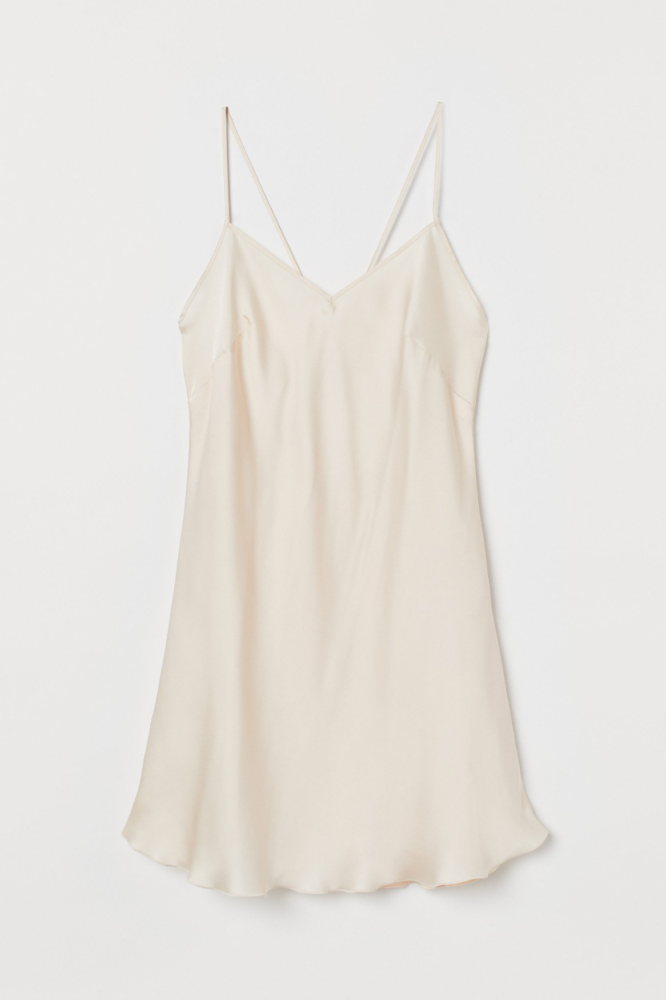
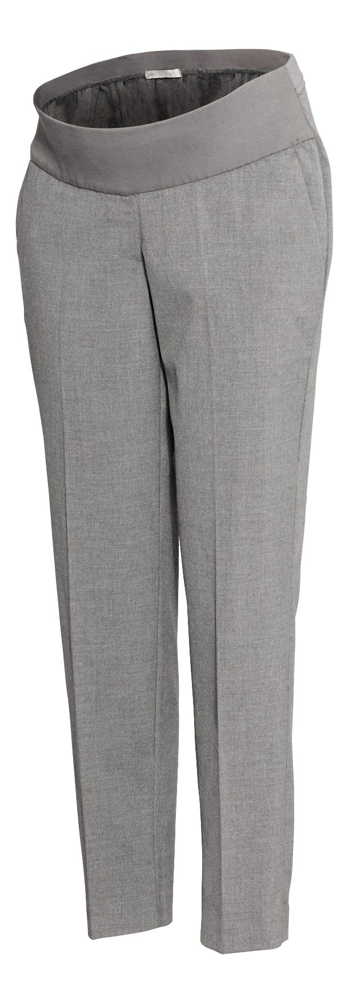
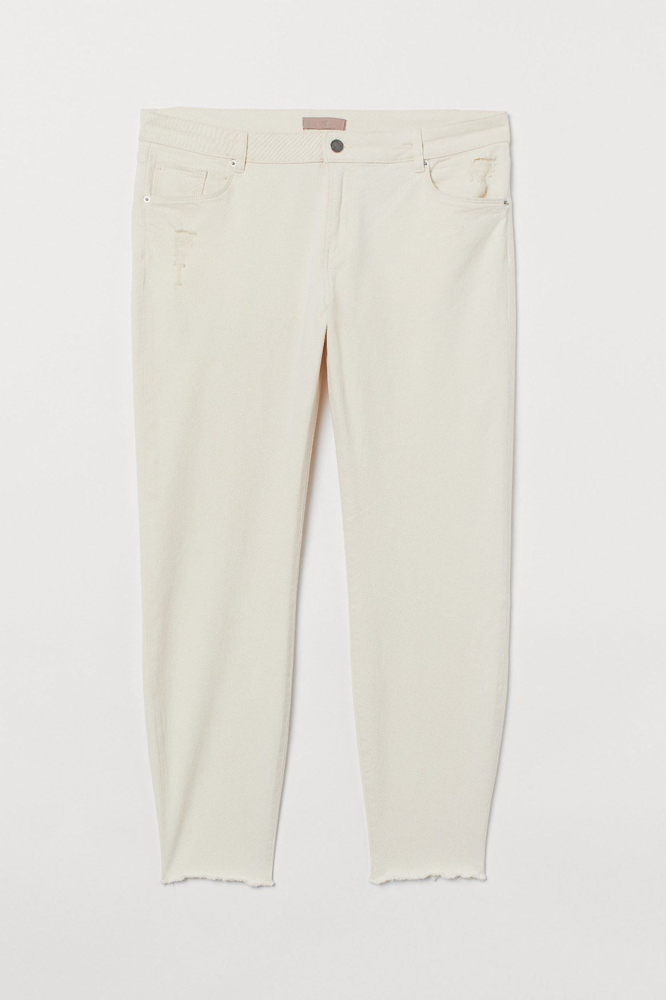
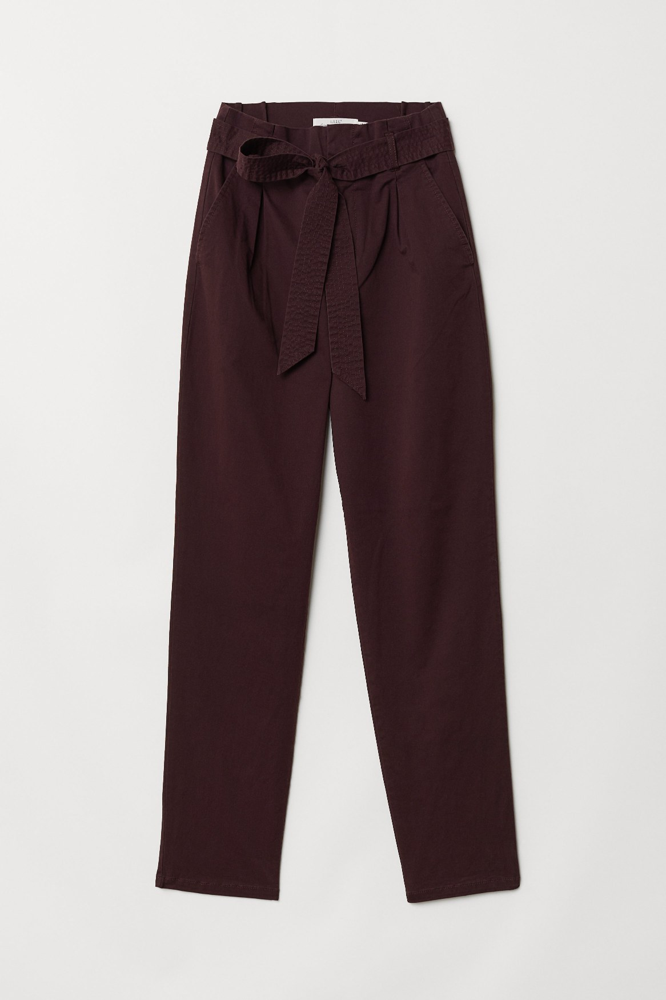
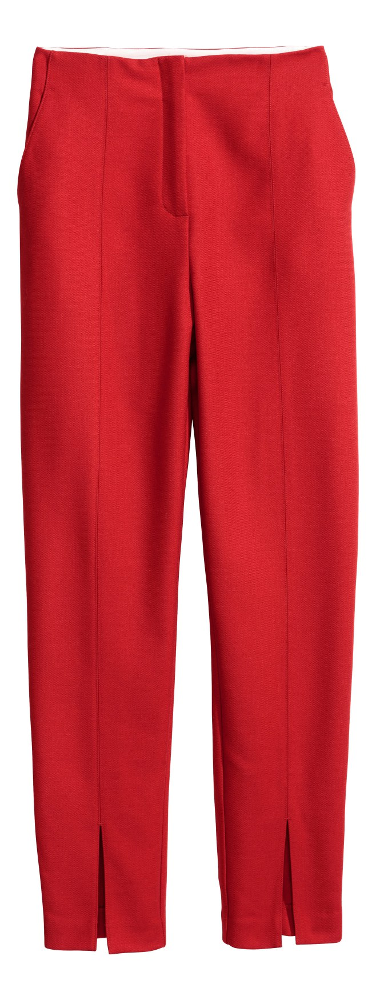
...
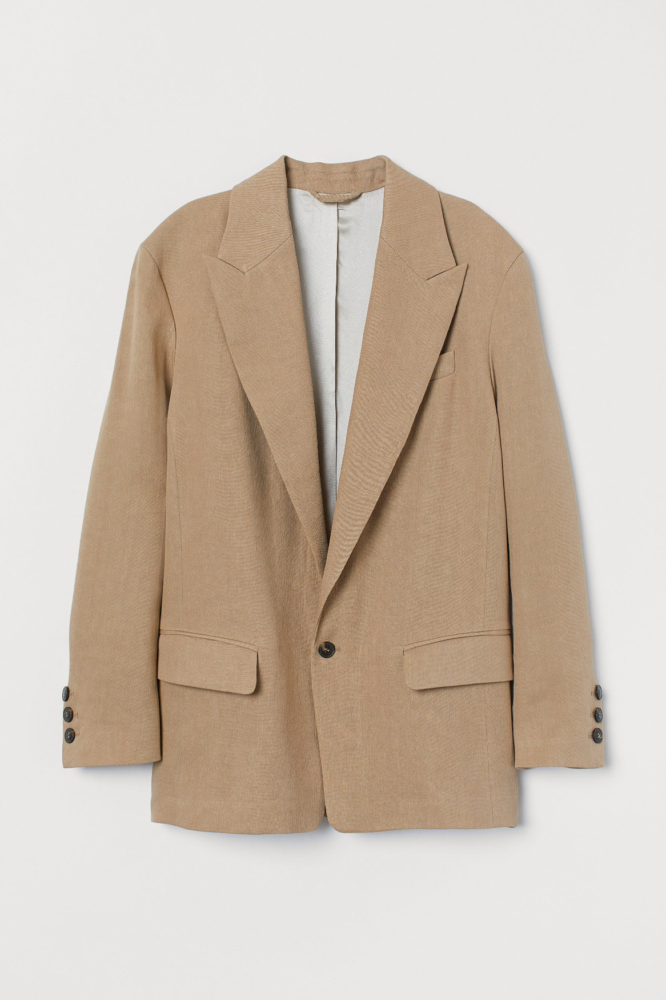
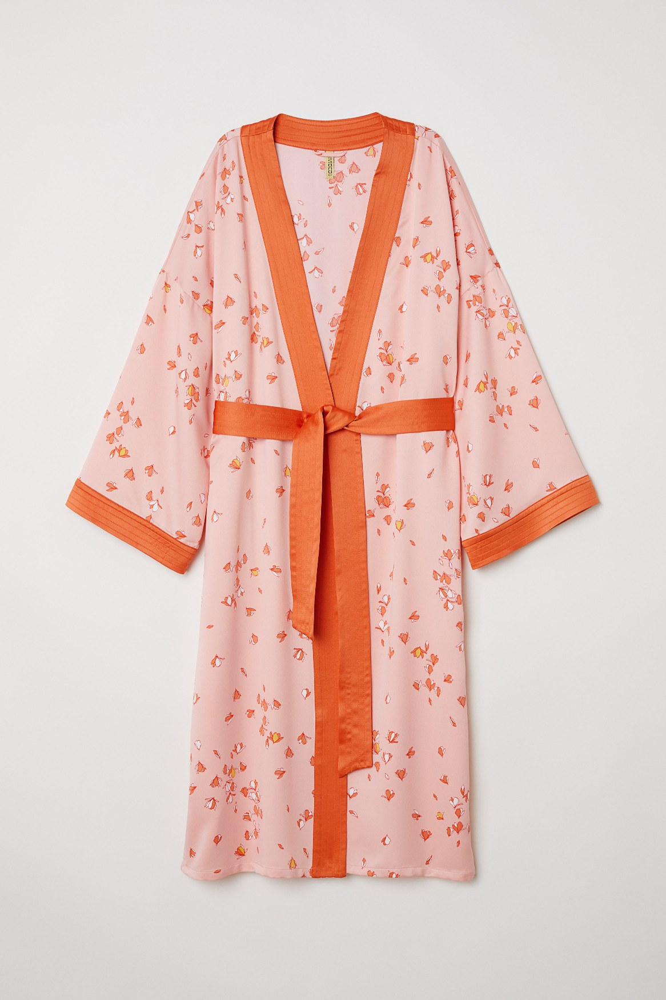
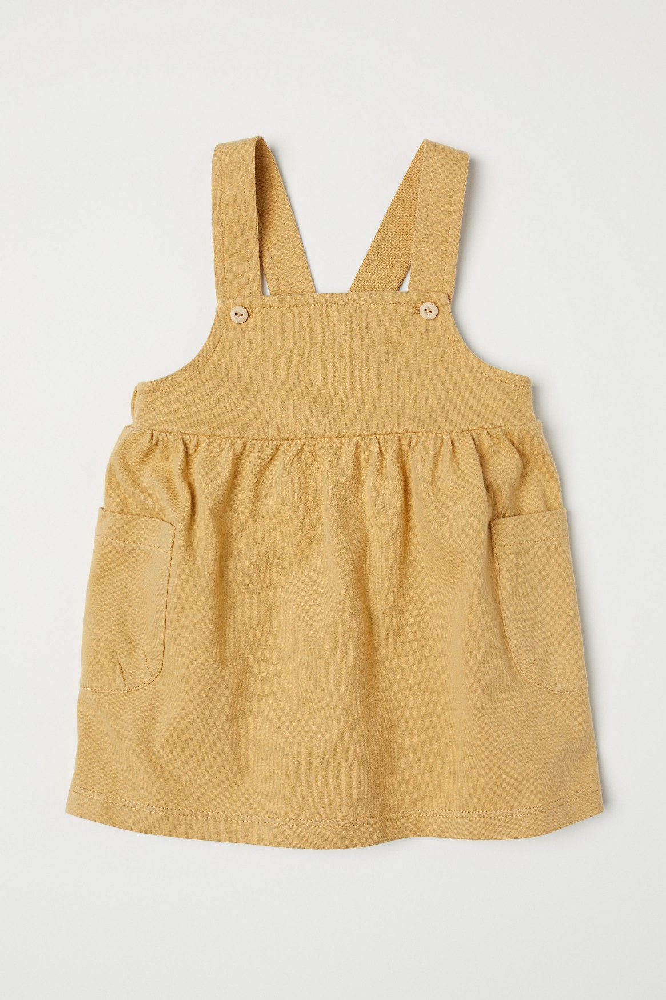
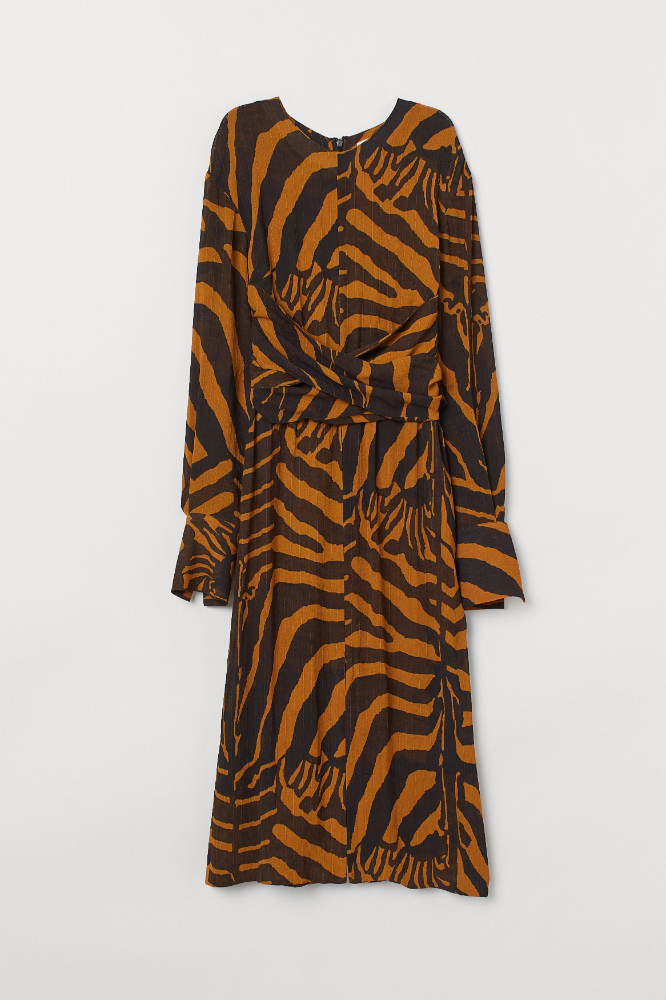
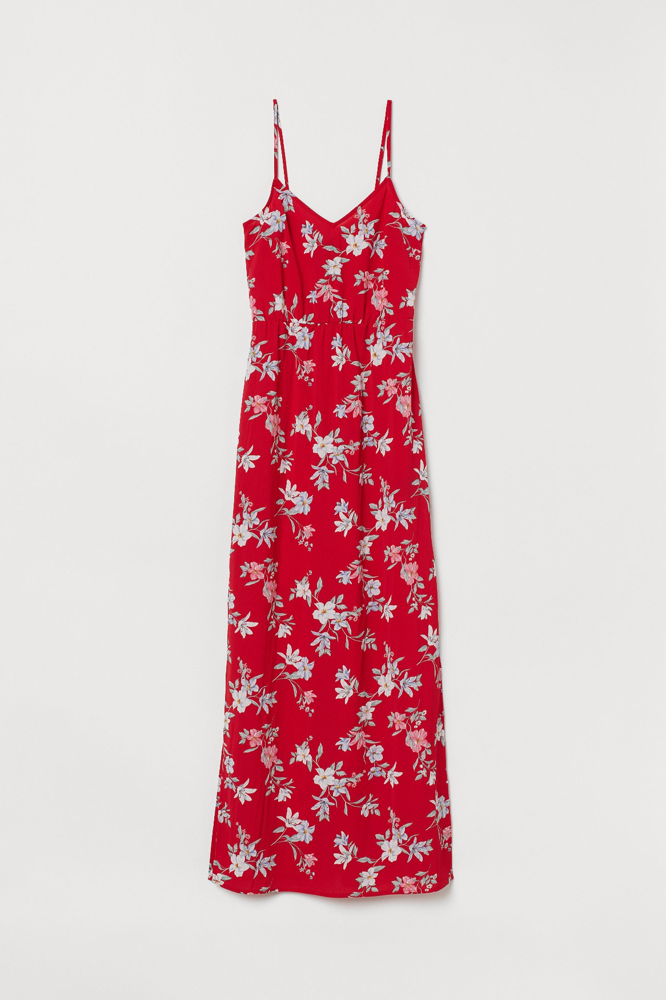

In [ ]:
from IPython.display import display, HTML
import contextlib
import io
import os
import base64

# Define some tricky, realistic queries for your case study
test_queries = [
    "formal red trousers for a gala",
    "black leather skirt for a rock concert",
    "formal red trousers for a gala",
    "oversized hoodie for running",
    "men floral short sleeve shirt",
    "men pink tailored blazer",
    "baby warm winter knit sweater",
    "goth white maxi dress",
    "minimalist all black summer beach dress",
    "yellow corporate business suit"
]

def get_image_base64(article_id):
    # H&M images are stored as 0{article_id}.jpg in folders grouped by the first 3 digits
    art_id = str(article_id).zfill(10)
    folder = art_id[:3]
    filename = f"{art_id}.jpg"
    img_path = f"images/{folder}/{filename}"

    # Check if the image exists locally
    if not os.path.exists(img_path):
        os.makedirs(f"images/{folder}", exist_ok=True)
        # Download just this specific image from Kaggle to save time and disk space
        os.system(f"kaggle competitions download -c h-and-m-personalized-fashion-recommendations -f {img_path} -p images/{folder} > /dev/null 2>&1")

        # Kaggle sometimes zips individual file downloads
        zip_path = f"images/{folder}/{filename}.zip"
        if os.path.exists(zip_path):
            os.system(f"unzip -o {zip_path} -d images/{folder} > /dev/null 2>&1")
            os.remove(zip_path)

    # If successfully downloaded, encode as base64 for HTML display
    if os.path.exists(img_path):
        with open(img_path, "rb") as f:
            return base64.b64encode(f.read()).decode('utf-8')
    return None

def get_html_table(df, title, border_color="#ccc"):
    if df is None or len(df) == 0:
        return f"<div style='border: 1px solid {border_color}; padding: 10px;'><h4>{title}</h4><p>No results found.</p></div>"

    html = f"<div style='border: 1px solid {border_color}; padding: 10px; border-radius: 5px;'>"
    html += f"<h4 style='text-align:center; margin-top:0;'>{title}</h4>"
    html += "<table style='width:100%; border-collapse: collapse; font-size: 12px;'>"
    html += "<tr style='background-color: #f2f2f2; border-bottom: 2px solid #ddd;'>"
    html += "<th style='padding:4px; width: 60px;'>Image</th>"
    html += "<th style='padding:4px;'>Name</th><th style='padding:4px;'>Type</th><th style='padding:4px;'>Color</th><th style='padding:4px;'>Description</th></tr>"

    for _, row in df.iterrows():
        desc = str(row['detail_desc'])
        short_desc = desc[:80] + "..." if len(desc) > 80 else desc

        # Fetch and encode image
        img_b64 = get_image_base64(row['article_id'])
        if img_b64:
            img_tag = f"<img src='data:image/jpeg;base64,{img_b64}' style='width:60px; height:auto; border-radius:4px;' />"
        else:
            img_tag = "<span style='color:#999; font-size:10px;'>No Image</span>"

        html += f"<tr style='border-bottom: 1px solid #eee;'>"
        html += f"<td style='padding:4px; text-align:center; vertical-align:middle;'>{img_tag}</td>"
        html += f"<td style='padding:4px;'><b>{row['prod_name']}</b></td>"
        html += f"<td style='padding:4px;'>{row['product_type_name']}</td>"
        html += f"<td style='padding:4px;'>{row['colour_group_name']}</td>"
        html += f"<td style='padding:4px;'><i>{short_desc}</i></td>"
        html += "</tr>"
    html += "</table></div>"
    return html

html_output = "<h2 style='color: #2c3e50;'>Qualitative Case Study: Baseline vs Hybrid (With Images)</h2>"
print("Running searches and downloading images... this may take a moment for the first run!")

for query in test_queries:
    html_output += f"<div style='background-color: #e8f4f8; padding: 10px; margin-top: 20px; border-radius: 5px;'><b>Query:</b> <i>'{query}'</i></div>"

    # Run searches silently
    with contextlib.redirect_stdout(io.StringIO()):
        baseline_df = baseline_search(query, top_k=3)
        hybrid_df = hybrid_search(query, top_k=3)

    html_output += "<div style='display: flex; gap: 15px; margin-top: 10px;'>"
    html_output += f"<div style='flex: 1;'>{get_html_table(baseline_df, 'Baseline (Dense Only)', '#e74c3c')}</div>"
    html_output += f"<div style='flex: 1;'>{get_html_table(hybrid_df, 'Hybrid (LLM + Dense)', '#27ae60')}</div>"
    html_output += "</div>"

from IPython.display import clear_output
clear_output()
display(HTML(html_output))